## Setting up NLTK

[NLTK](https://www.nltk.org/) — the **Natural Language Toolkit** — is a widely used Python library for teaching and experimenting with NLP.

It provides tools for tasks such as:

- tokenisation
- stop-word handling
- stemming
- lemmatisation
- part-of-speech tagging
- parsing
- access to linguistic datasets

We will use NLTK for the introductory processing stages.

In [1]:
import nltk

# Download the small resources used in this notebook.
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("NLTK is ready.")

ModuleNotFoundError: No module named 'nltk'

## Tokenisation

**Tokenisation** means splitting text into smaller units called **tokens**.

A token might be:

- a word;
- a number;
- punctuation;
- or another meaningful unit, depending on the tokenizer.

For an introductory example, word tokenisation is enough.

### Example

```text
"The intelligent agent learns from text."
```

might become:

```text
["The", "intelligent", "agent", "learns", "from", "text", "."]
```

Tokenisation is important because many later NLP operations work on individual tokens.

In [ ]:
from nltk.tokenize import word_tokenize

text = "The intelligent agent learns from text."

tokens = word_tokenize(text)

print(tokens)
print("Number of tokens:", len(tokens))

['The', 'intelligent', 'agent', 'learns', 'from', 'text', '.']
Number of tokens: 7


### Normalisation

**Normalisation** attempts to make text more consistent.

A very simple example is converting text to lowercase:

```text
"Agent" → "agent"
```

This can reduce the number of distinct forms that a system needs to consider.

**When normalisation helps:**

- *Search engines* — a user searching for "agent" should also find documents containing "Agent" or "AGENT". Lowercasing lets these match.
- *Topic modelling / bag-of-words counting* — "Python" at the start of a sentence and "python" mid-sentence should usually be counted as the same word.

However, normalisation can also remove information. For example, capitalisation may sometimes be meaningful.

**When normalisation can hurt:**

- *Named-entity recognition* — "Apple" (the company) vs "apple" (the fruit), or "May" (the month/name) vs "may" (the verb). Lowercasing destroys this distinction.
- *Sentiment analysis* — "This is GREAT" often signals stronger emphasis or sarcasm than "this is great". Lowercasing can flatten that signal.
- *Acronym detection* — "US" (United States) vs "us" (the pronoun) become indistinguishable once lowercased.

So normalisation is a **task-dependent design choice**, not a rule that should always be applied.

In [ ]:
text = "The Agent works with Natural Language."

lower_text = text.lower()

print("Original:", text)
print("Lowercase:", lower_text)

Original: The Agent works with Natural Language.
Lowercase: the agent works with natural language.


## Removing punctuation

For some NLP tasks, punctuation is not useful as a feature. We can filter it out.

For this demonstration we will keep alphabetic tokens only.

> **Important:** In real NLP systems, punctuation should not automatically be removed. For example, sentiment, emotion, dialogue and language modelling can sometimes benefit from punctuation.

In [ ]:
tokens = word_tokenize(text.lower())

words_only = [token for token in tokens if token.isalpha()]

print("All tokens:", tokens)
print("Words only:", words_only)

All tokens: ['the', 'agent', 'works', 'with', 'natural', 'language', '.']
Words only: ['the', 'agent', 'works', 'with', 'natural', 'language']


## Stop words

**Stop words** are very common words that are sometimes removed because they carry relatively little useful information for a particular task.

Examples in English include:

- the
- is
- are
- and
- of
- to

NLTK provides a list of English stop words.

### Important caveat

Stop-word removal is **not always appropriate**.

For example, in a question-answering system, a word such as *“not”* can be extremely important:

> “The service is **not** available.”

Removing *not* could change the meaning.

Therefore:

> **Do not think of preprocessing steps as universally correct. Choose them according to the task.**

In [ ]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

filtered_words = [
    word for word in words_only
    if word not in stop_words
]

print("Before stop-word removal:", words_only)
print("After stop-word removal: ", filtered_words)

Before stop-word removal: ['the', 'agent', 'works', 'with', 'natural', 'language']
After stop-word removal:  ['agent', 'works', 'natural', 'language']


## Stemming

**Stemming** reduces words to a simplified root-like form by applying rules.

For example, several related words may be reduced to something similar:

```text
playing
played
plays
```

A stemmer does not necessarily produce a valid English word. It is primarily a computational shortcut for grouping related forms.

NLTK includes the **Porter Stemmer**.

In [ ]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

example_words = ["play", "playing", "played", "plays", "studies", "studying"]

for word in example_words:
    print(f"{word:10} -> {stemmer.stem(word)}")

play       -> play
playing    -> play
played     -> play
plays      -> play
studies    -> studi
studying   -> studi


### What should we notice?

Stemming is fast and simple, but its output can look unusual.

For example, a stem may not be a normal dictionary word.

That leads us to **lemmatisation**.

## Lemmatisation

**Lemmatisation** attempts to reduce a word to its **lemma** — a valid dictionary/base form.

For example:

```text
running → run
better  → better
cars    → car
```

The process can use linguistic knowledge, making it generally more linguistically informed than simple stemming.

For this introductory example, we will use NLTK's WordNet lemmatiser.

In [ ]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

example_words = ["cars", "dogs", "playing", "played", "studies"]

for word in example_words:
    print(f"{word:10} -> {lemmatizer.lemmatize(word)}")

cars       -> car
dogs       -> dog
playing    -> playing
played     -> played
studies    -> study


## Putting the basic steps together

Let's process a short sentence using several of the ideas introduced so far.

We will:

1. start with raw text;
2. lowercase it;
3. tokenise it;
4. keep alphabetic tokens;
5. remove stop words;
6. lemmatise the remaining words.

This is a deliberately simple pipeline — real NLP systems can be much more sophisticated.

In [ ]:
text = "Intelligent agents are learning from different documents and documents are useful."

# 1. Lowercase
text_lower = text.lower()

# 2. Tokenise
tokens = word_tokenize(text_lower)

# 3. Keep alphabetic tokens
words = [token for token in tokens if token.isalpha()]

# 4. Remove stop words
words_no_stop = [word for word in words if word not in stop_words]

# 5. Lemmatise
lemmas = [lemmatizer.lemmatize(word) for word in words_no_stop]

print("Original:          ", text)
print("Tokens:            ", tokens)
print("Words only:        ", words)
print("Without stopwords: ", words_no_stop)
print("Lemmas:            ", lemmas)

Original:           Intelligent agents are learning from different documents and documents are useful.
Tokens:             ['intelligent', 'agents', 'are', 'learning', 'from', 'different', 'documents', 'and', 'documents', 'are', 'useful', '.']
Words only:         ['intelligent', 'agents', 'are', 'learning', 'from', 'different', 'documents', 'and', 'documents', 'are', 'useful']
Without stopwords:  ['intelligent', 'agents', 'learning', 'different', 'documents', 'documents', 'useful']
Lemmas:             ['intelligent', 'agent', 'learning', 'different', 'document', 'document', 'useful']


## What have we achieved?

We have transformed human-readable text into a more structured representation.

However, there is an important limitation:

> A list of words is not yet a rich numerical representation of meaning.

For example, consider:

```text
"The cat sat on the mat."
"The kitten sat on the rug."
```

A simple system can identify that *cat* and *kitten* are different tokens. But how can a computer represent the fact that they occur in similar contexts?

This is where **word embeddings** become useful.

# Part 2 — Word2Vec




## A worked example

Imagine the sentence:

```text
The cat drinks milk
```

Using a small context window, we could create relationships such as:

```text
cat   → drinks
drinks → cat
drinks → milk
milk  → drinks
```

With a larger collection of sentences, the model sees many such relationships.

The learning process adjusts the word vectors so that words occurring in similar contexts develop related representations.

The resulting vectors might look conceptually like:

```text
cat      → [ 0.21, -0.15,  0.72, ...]
kitten   → [ 0.24, -0.13,  0.70, ...]
car      → [-0.81,  0.31, -0.22, ...]
```

**These numbers are learned by the model.** They are not manually assigned meanings such as “animal = 0.7”.

## Install/import Gensim

For our coding demonstration we will use **Gensim**, a Python library commonly used for topic modelling and word-vector techniques.



In [1]:
!pip -q install gensim


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
from gensim.models import Word2Vec

print("Gensim Word2Vec imported successfully.")

Gensim Word2Vec imported successfully.


## Our tiny training corpus

To keep the demonstration understandable, we will deliberately use a **very small corpus**.

Each inner list represents one sentence that has already been tokenised.

Notice that the examples deliberately reuse words in related contexts.

> **Important:** This tiny corpus is for teaching the mechanism. It is far too small to create a useful real-world language model.

In [3]:
sentences = [
    ["the", "cat", "drinks", "milk"],
    ["the", "kitten", "drinks", "milk"],
    ["the", "cat", "eats", "fish"],
    ["the", "kitten", "eats", "fish"],
    ["the", "dog", "drinks", "water"],
    ["the", "dog", "eats", "meat"],
    ["the", "puppy", "drinks", "water"],
    ["the", "puppy", "eats", "meat"],
    ["the", "car", "drives", "fast"],
    ["the", "bus", "drives", "fast"],
]

for sentence in sentences:
    print(sentence)

['the', 'cat', 'drinks', 'milk']
['the', 'kitten', 'drinks', 'milk']
['the', 'cat', 'eats', 'fish']
['the', 'kitten', 'eats', 'fish']
['the', 'dog', 'drinks', 'water']
['the', 'dog', 'eats', 'meat']
['the', 'puppy', 'drinks', 'water']
['the', 'puppy', 'eats', 'meat']
['the', 'car', 'drives', 'fast']
['the', 'bus', 'drives', 'fast']


## Train a small Word2Vec model

The important parameters here are intentionally kept simple:

- `vector_size` — how many numbers represent each word;
- `window` — how many words around a target word are considered as context;
- `min_count` — ignore words that occur fewer times than this threshold;
- `sg=1` — use the Skip-gram approach;
- `epochs` — how many training passes are made over the corpus.

Because the corpus is tiny, the vectors should be treated as **illustrative rather than statistically reliable**.

In [4]:
model = Word2Vec(
    sentences=sentences,
    vector_size=20,
    window=2,
    min_count=1,
    sg=1,
    epochs=100,
    seed=42
)

print("Vocabulary size:", len(model.wv))
print("Vocabulary:", list(model.wv.key_to_index.keys()))

Vocabulary size: 15
Vocabulary: ['the', 'eats', 'drinks', 'fast', 'drives', 'puppy', 'meat', 'water', 'dog', 'fish', 'kitten', 'milk', 'cat', 'bus', 'car']


## Inspect a word vector

Each word now has a vector containing 20 numerical values.

Let's inspect the vector for **cat**.

In [5]:
cat_vector = model.wv["cat"]

print("Vector for 'cat':")
print(cat_vector)
print()
print("Vector length:", len(cat_vector))

Vector for 'cat':
[-0.03597983  0.00869562 -0.04064188  0.01530128  0.01304121 -0.04070795
  0.02501425 -0.00802132  0.02859811 -0.04613651 -0.03189741 -0.00036997
 -0.0308836  -0.0169496   0.01690178 -0.03597792  0.01753147 -0.04051263
 -0.0322443   0.00881984]

Vector length: 20


### What does the vector mean?

Do **not** interpret an individual number as a human-readable feature.

For example, if the vector begins:

```text
[0.12, -0.34, 0.08, ...]
```

we cannot simply say:

> “The first number means animal-ness.”

The meaning is distributed across the dimensions.

What matters most for our introductory discussion is the **relationship between vectors**.

## Finding similar words

One of the most useful demonstrations is to ask the model:

> Which words have vectors most similar to the vector for `cat`?

Gensim provides `most_similar()` for this.

In [6]:
similar_to_cat = model.wv.most_similar("cat", topn=5)

for word, score in similar_to_cat:
    print(f"{word:10} similarity = {score:.3f}")

milk       similarity = 0.384
eats       similarity = 0.349
meat       similarity = 0.227
kitten     similarity = 0.191
fish       similarity = 0.120


### How should we interpret this?

The similarity score is based on the relationship between the learned vectors.

A high score means:

> The model's vector representation places the two words close together in the learned vector space.

It does **not** mean that the model has a human-like understanding of the words.

Because our corpus is tiny, the exact ranking may be surprising. That is actually useful for discussion: **training data strongly affects what an embedding learns.**

## Compare several word relationships

Let's inspect similarities for a few pairs.

We expect words appearing in similar contexts to have some relationship in the vector space.

We can use cosine similarity, which compares the orientation of two vectors.

In [7]:
from numpy import dot
from numpy.linalg import norm

# This measures the angle between the two vectors — 1.0 means identical direction (highly related), 0 means unrelated, negative means opposite.
def cosine_similarity(word1, word2):
    v1 = model.wv[word1]
    v2 = model.wv[word2]
    return dot(v1, v2) / (norm(v1) * norm(v2))

pairs = [
    ("cat", "kitten"),
    ("dog", "puppy"),
    ("cat", "car"),
    ("dog", "car"),
]

for word1, word2 in pairs:
    score = cosine_similarity(word1, word2)
    print(f"{word1:6} ↔ {word2:6} : {score:.3f}")

    

cat    ↔ kitten : 0.191
dog    ↔ puppy  : -0.055
cat    ↔ car    : -0.248
dog    ↔ car    : 0.107


## A simple visualisation

A word vector may contain many dimensions. Our model has 20 dimensions, which cannot be directly visualised on a normal 2D graph.

We can use a simple dimensionality-reduction technique such as **PCA** to project the vectors into two dimensions.

> This is only for visual intuition. Reducing 20 dimensions to 2 necessarily loses information.

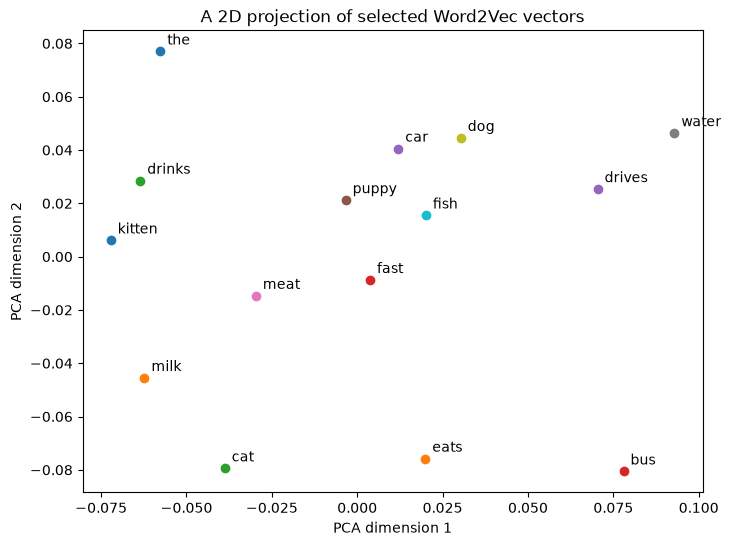

In [8]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

#words_to_plot = ["cat", "kitten", "dog", "puppy", "car", "bus", "milk", "water"]
words_to_plot = list(model.wv.key_to_index.keys())

vectors = [model.wv[word] for word in words_to_plot]

pca = PCA(n_components=2)
vectors_2d = pca.fit_transform(vectors)

plt.figure(figsize=(8, 6))

for word, (x, y) in zip(words_to_plot, vectors_2d):
    plt.scatter(x, y)
    plt.annotate(word, (x, y), xytext=(5, 5), textcoords="offset points")

plt.title("A 2D projection of selected Word2Vec vectors")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.show()